<a href="https://colab.research.google.com/github/amrutha-pullaikodi/Bank-system-using-opps/blob/main/statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Statistics Project

In [64]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.stats import skew

In [65]:
data=pd.read_csv("/content/customer_behavior.csv")
data

,CustomerID,Gender,Region,PurchaseAmount,ProductCategory,Churn,CampaignGroup
0,1001,Male,South,256.07,Fashion,No,A
1,1002,Female,South,NaN,Electronics,Yes,B
2,1003,Female,West,1194.41,Fashion,No,A
3,1004,Female,South,413.06,Grocery,No,A
4,1005,Male,West,1556.32,Fashion,Yes,A
...,...,...,...,...,...,...,...
4995,5996,Female,West,1497.00,Electronics,Yes,B
4996,5997,Male,West,978.87,Fashion,Yes,A
4997,5998,Male,West,906.93,Fashion,No,NaN
4998,5999,Female,South,375.67,Fashion,No,NaN


1. What is the average, median, and mode of PurchaseAmount?

In [66]:
print("average = ",data["PurchaseAmount"].mean())
print("median = ",data["PurchaseAmount"].median())
print("mode = ",data["PurchaseAmount"].mode())

average =  1003.9506701030928
median =  998.0799999999999
mode =  0    0.0
Name: PurchaseAmount, dtype: float64


2. Are there any outliers in the PurchaseAmount data?

Outliers= [2318.33, 2496.41, 2688.69, 2349.16, 2578.89, 2384.19, 2457.05, 2316.19, 2400.69, 2357.41, 2688.88, 2643.88, 2472.62, 2484.75, 2642.06]


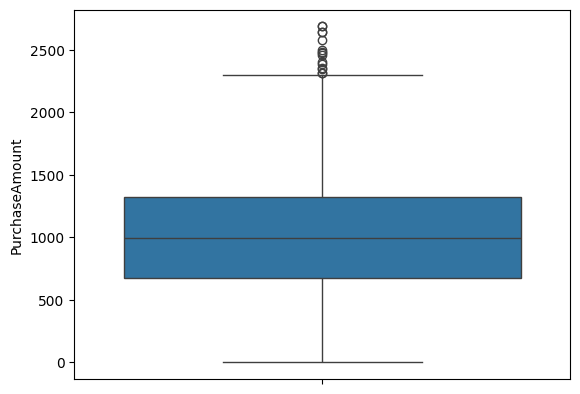

In [67]:
sns.boxplot(data["PurchaseAmount"])
q1=data["PurchaseAmount"].quantile(.25)
q3=data["PurchaseAmount"].quantile(.75)
IQR=q3-q1
lower_lmt=q1-1.5*IQR
upper_lmt=q3+1.5*IQR
outlier=[]
for i in data["PurchaseAmount"]:
  if i<lower_lmt or i>upper_lmt:
    outlier.append(i)
print("Outliers=",outlier)

3. Is there any skewness or kurtosis in the PurchaseAmount distribution?

0.10605907900111372
Skewness: 0.10605907900111372
Kurtosis: -0.2615105545319705


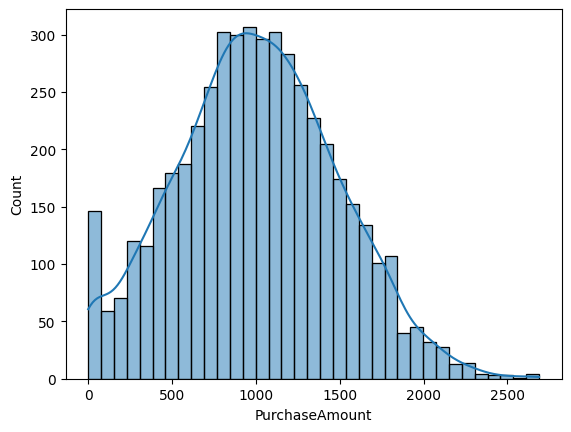

In [68]:
sns.histplot(data["PurchaseAmount"],kde=True)
skewness = skew(data["PurchaseAmount"].dropna())
print(skewness)
kurtosis = data["PurchaseAmount"].kurt()

print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

Observation:Skewness is 0.1061, which indicates a very slight positive (right) skew.

Kurtosis is -0.2615, indicating a slightly platykurtic distribution

4. Is there a significant difference in spending between male and female
customers?

In [69]:
from scipy import stats
male = data[data["Gender"] == "Male"]["PurchaseAmount"].dropna()

female = data[data["Gender"] == "Female"]["PurchaseAmount"].dropna()

t_stat, p_value = stats.ttest_ind(
    male, female)
#equal_var=False


print("Male average:", male.mean())
print("Female average:", female.mean())
print("P-value:", p_value)

Male average: 1019.1766093880973
Female average: 987.8720464135021
P-value: 0.025471167149519254


Observation:Male customers have a higher average PurchaseAmount (1019.18) compared to female customers (987.87).

5. Is there a relationship between ProductCategory and customer churn?

In [70]:
from scipy.stats import chi2_contingency
data_new = pd.crosstab(
    data["ProductCategory"],#.dropna(),
    data["Churn"]#.dropna()
)

chi2, p_value, dof, expected = chi2_contingency(data_new)

print(data_new)
print("Chi-square:", chi2)
print("P-value:", p_value)

Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
Chi-square: 0.3960436652673918
P-value: 0.8203519424988512


There is no statistically significant relationship between ProductCategory and customer churn.

6. Does PurchaseAmount vary significantly across different regions?

In [71]:
groups = [
    group["PurchaseAmount"].dropna()
    for name, group in data.groupby("Region")
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)
if p_value<.05:
  print("At least one region is significantly different")
else:
  print("\nThere is no statistically significant difference in average PurchaseAmount across the four regions")

F-statistic: 0.38966786354806704
P-value: 0.760452802731563

There is no statistically significant difference in average PurchaseAmount across the four regions


7. Which email campaign (A or B) performed better in terms of average
PurchaseAmount?

In [72]:
campaign = data.groupby("CampaignGroup")["PurchaseAmount"].mean()

print(campaign)

A = data[data["CampaignGroup"] == "A"]["PurchaseAmount"].dropna()

B = data[data["CampaignGroup"] == "B"]["PurchaseAmount"].dropna()

t_stat, p_value = stats.ttest_ind(
    A, B, equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

CampaignGroup
A    1011.945587
B     994.339965
Name: PurchaseAmount, dtype: float64
T-statistic: 1.2430861943551852
P-value: 0.21389858277292212


Campaign A has a higher average PurchaseAmount than Campaign B.
However, the p-value is greater than 0.05, meaning the difference is not statistically significant.

8. Can we assume PurchaseAmount follows a normal distribution?

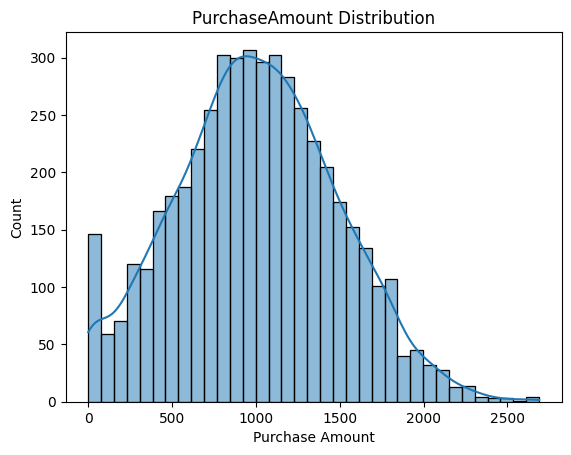

This means Purchase Amount does not strictly follow a normal distribution


In [76]:

from statsmodels.stats.weightstats import ztest
sns.histplot(data["PurchaseAmount"], kde=True)
plt.title("PurchaseAmount Distribution")
plt.xlabel("Purchase Amount")
plt.show()

z,p=ztest(data["PurchaseAmount"])
if p<0.05:
  print("Since the p-value is less than 0.05, we reject the null hypothesis.")
else:
  print("This means Purchase Amount does not strictly follow a normal distribution")

9. What insights can we gain by applying the Central Limit Theorem?

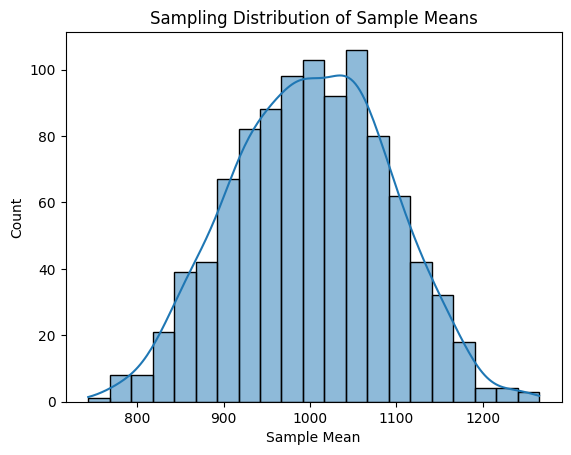

In [80]:
sample_means = []
df=data["PurchaseAmount"].dropna()
for i in range(1000):
    sample = df.sample(
        n=30,
        replace=True,
        random_state=i
    )

    sample_means.append(sample.mean())

sns.histplot(sample_means, kde=True)

plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.show()

The Central Limit Theorem demonstrates that the sampling distribution of sample means approaches a normal distribution when sufficiently large random samples are taken.

10.What is the 95% confidence interval for the average PurchaseAmount?

In [78]:
df = data["PurchaseAmount"].dropna()

mean = df.mean()
std = df.std()
n = len(df)

se = std / np.sqrt(n)

t_critical = stats.t.ppf(0.975, df=n-1)

lower = mean - (t_critical * se)
upper = mean + (t_critical * se)

print("Mean:", mean)
print("Lower limit:", lower)
print("Upper limit:", upper)

Mean: 1003.9506701030928
Lower limit: 990.3789594609216
Upper limit: 1017.522380745264


 95% confidence interval 990.3789594609216 to 1017.52238074